In [1]:
#import needed packages
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np
from copy import deepcopy as cdc

from datetime import datetime as dt
import re
def extract_timestamps(series:pd.Series) -> pd.Series:
    timestamp = series.str.extract('_(\d{4}-[\-\d_T]*)DLC', expand=False)
    return pd.to_datetime(timestamp, format="%Y-%m-%dT%H_%M_%S")
##need to have filename column as type str in order for datetime extraction to be used, won't run on Posix type

import statsmodels.api as sm
from statsmodels.formula.api import ols
from scipy import stats

import prey_capture_python as preycap
# import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [3]:
#load flattened geos file, this geos file doesnt have the metadata of condition and laser value
geos_df=pd.read_csv('/Volumes/Projects/PreyCapture/ZIActivation/clipped_geos_cleaned_allmice_alltrials_nonans_fames.csv')

In [15]:
geos_df

,Unnamed: 0,filename,localframe,dist,az,mouse_spd,cricket_spd
0,0,/Volumes/Projects/PreyCapture/ZIActivation/202...,1087,11.713119,171.506417,6.418692,139.121474
1,1,/Volumes/Projects/PreyCapture/ZIActivation/202...,1088,12.039882,179.091308,7.832069,130.150670
2,2,/Volumes/Projects/PreyCapture/ZIActivation/202...,1089,12.077035,175.622398,8.852334,141.281868
3,3,/Volumes/Projects/PreyCapture/ZIActivation/202...,1090,12.172264,172.377686,9.765431,150.217841
4,4,/Volumes/Projects/PreyCapture/ZIActivation/202...,1091,12.683908,163.427985,8.215556,151.200106
...,...,...,...,...,...,...,...
6871091,6871091,/Volumes/Projects/PreyCapture/ZIActivation/202...,9778,3.827463,15.730165,31.409355,13.160123
6871092,6871092,/Volumes/Projects/PreyCapture/ZIActivation/202...,9779,3.702472,15.736844,30.618819,11.743372
6871093,6871093,/Volumes/Projects/PreyCapture/ZIActivation/202...,9780,3.610869,13.730883,28.749787,7.466669
6871094,6871094,/Volumes/Projects/PreyCapture/ZIActivation/202...,9781,3.636880,16.927689,31.135584,6.499485


In [18]:
def intercepts_dataframe(df: pd.DataFrame,
                         az_thresh: float = 30,
                         speed_thresh: float = 5,
                         dist_thresh: float = 5) -> pd.DataFrame:
    """
    Returns a DataFrame with intercept info per filename.

    Output columns:
        - 'filename': unique trial name
        - 'intercept_indices': list of global DataFrame indices where intercepts occurred
        - 'intercept_localframes': list of localframe values corresponding to intercepts
    """
    results = []

    for filename, sub_df in df.groupby('filename'):
        sub_df = sub_df.copy()
        sub_df = sub_df.sort_index()  # Ensure correct order

        # Define approach condition
        is_approach = (sub_df['az'].abs() < az_thresh) & (sub_df['mouse_spd'] > speed_thresh)
        approach_bool = is_approach.astype(int)
        diff = approach_bool.diff().fillna(0)

        starts = sub_df.index[diff == 1].tolist()
        ends = sub_df.index[diff == -1].tolist()

        # Edge case handling
        if approach_bool.iloc[0] == 1:
            starts = [sub_df.index[0]] + starts
        if approach_bool.iloc[-1] == 1:
            ends = ends + [sub_df.index[-1]]

        approach_periods = list(zip(starts, ends))

        # Get intercepts: approach ends with dist < threshold
        intercept_indices = []
        intercept_localframes = []

        for start_idx, end_idx in approach_periods:
            if end_idx in df.index and df.loc[end_idx, 'dist'] < dist_thresh:
                intercept_indices.append(end_idx)
                intercept_localframes.append(df.loc[end_idx, 'localframe'])

        results.append({
            'filename': filename,
            'intercept_indices': intercept_indices,
            'intercept_localframes': intercept_localframes
        })

    return pd.DataFrame(results)


In [20]:
intercept_df = intercepts_dataframe(geos_df)
intercept_df

,filename,intercept_indices,intercept_localframes
0,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[426, 438, 513, 624, 678, 703, 739, 771, 807]","[1570, 1582, 1657, 1782, 1907, 1932, 2493, 258..."
1,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[1207, 1224, 1228, 1235, 1263, 1292, 1298, 141...","[1707, 1753, 1774, 1810, 1859, 1888, 1917, 236..."
2,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[4387, 4391, 4393, 4441, 4511, 4542, 4547, 456...","[4135, 4139, 4141, 4202, 4577, 4608, 4613, 484..."
3,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[8073, 8120, 8185, 8189, 8373, 8532, 8571, 861...","[4830, 4897, 5012, 5016, 5213, 5438, 5490, 553..."
4,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[8732, 10239, 10250, 10260, 10457, 10509, 1051...","[1211, 2839, 2850, 2860, 3162, 3214, 3216, 355..."
...,...,...,...
1080,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[6828093, 6828098, 6828100, 6828177, 6828311, ...","[2490, 2495, 2497, 2574, 2837, 3326, 3521, 355..."
1081,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[6832911, 6832919]","[3923, 3931]"
1082,/Volumes/Projects/PreyCapture/ZIActivation/202...,[],[]
1083,/Volumes/Projects/PreyCapture/ZIActivation/202...,"[6838498, 6838863, 6850403, 6850818, 6850820, ...","[7039, 7621, 19454, 28161, 28189, 38867, 38869..."


In [21]:
metadata_csv_test

,filename,folder_path,condition,laser_value,captureT,cricketdrop,captureframe,freqapproach,timetoapproach,prob_inter,prob_capture,timetointercept,interceptframe,c_length,capduration,trials_to_drop,corrected_interceptframe,corrected_timetointercept,corrected_capduration
Unnamed: 0,,,,,,,,,,,,,,,,,,,
132,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-15_10-01-12_mouse-0897,1,0.0,8.070,1082.0,2696.0,0.116505,1.425,1.000000,0.500000,5.715,1143.0,12.67000,2.355,NaN,1143.0,0.305,7.765
133,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-15_10-21-03_mouse-0898,1,0.0,6.425,1299.0,2584.0,0.135166,1.150,1.000000,0.333333,2.450,490.0,9.13875,3.975,NaN,1693.0,1.97,4.455
134,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-15_10-23-08_mouse-0898,1,0.0,21.990,1029.0,5427.0,0.166412,5.025,0.500000,0.333333,16.445,3289.0,12.04850,5.545,NaN,3289.0,11.3,10.690
135,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-15_10-25-25_mouse-0898,1,0.0,21.860,1170.0,5542.0,0.163778,15.225,0.666667,0.250000,18.140,3628.0,12.87850,3.720,NaN,3628.0,12.29,9.570
136,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-15_10-27-44_mouse-0898,1,0.0,22.940,1090.0,5678.0,0.165798,0.075,0.428571,0.333333,0.755,151.0,13.93075,22.185,NaN,1207.0,0.585,22.355
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2435,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-25-16_mouse-1430,2,1.0,22.525,1805.0,6310.0,0.141276,1.945,0.666667,0.250000,6.905,1381.0,9.36850,15.620,left_only,2489,3.42,19.105
2436,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-27-15_mouse-1430,2,0.0,12.125,1513.0,3938.0,0.197472,0.250,0.200000,1.000000,11.625,2325.0,10.74700,0.500,left_only,2325.0,4.06,8.065
2437,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-29-34_mouse-1430,2,1.0,6.740,1766.0,3114.0,0.040080,6.185,1.000000,1.000000,6.720,1344.0,10.24200,0.020,left_only,1997,1.155,5.585


In [5]:
metadata_csv=metadata_csv.set_index('Unnamed: 0')
metadata_csv

NameError: name 'metadata_csv' is not defined

In [6]:
test_metadata.index

NameError: name 'test_metadata' is not defined

In [7]:
metadata_indices

array([ 132,  133,  134, ..., 2437, 2438, 2439])

In [9]:
error_indices

array([ 133,  136,  137,  138,  139,  141,  142,  144,  147,  148,  151,
        152,  224,  225,  226,  227,  228,  229,  231,  232,  235,  239,
        241,  242,  244,  245,  246,  247,  249,  250,  251,  253,  254,
        255,  256,  257,  258,  259,  260,  261,  262,  264,  267,  268,
        269,  270,  272,  273,  277,  279,  280,  282,  284,  285,  287,
        288,  289,  290,  291,  292,  293,  294,  297,  298,  301,  302,
        303,  304,  305,  307,  308,  309,  310,  312,  313,  314,  315,
        316,  322,  323,  324,  326,  328,  329,  330,  332,  334,  335,
        337,  338,  339,  340,  341,  342,  343,  344,  345,  346,  347,
        348,  350,  351,  352,  354,  356,  357,  360,  361,  362,  363,
        364,  366,  367,  369,  371,  372,  373,  374,  375,  376,  377,
        378,  379,  380,  381,  382,  383,  385,  386,  387,  388,  389,
        391,  392,  393,  394,  396,  397,  398,  399,  400,  401,  402,
        403,  404,  406,  407,  408,  409,  410,  4

In [4]:
#read in metadata and align to geos file to separate out different conditions
metadata_csv=pd.read_csv('/Volumes/Projects/PreyCapture/ZIActivation/metadata_alltrials.csv')
#subset the metadata to only contain filename, condition and laser value
metadata_small=metadata_csv[['filename', 'condition', 'laser_value']]

#drop the new index and used first column as the index, this is an identifier that matches the original opto_metrics output df
metadata_csv_test=metadata_csv.set_index('Unnamed: 0')
metadata_csv_test['corrected_interceptframe']=np.nan
metadata_csv_test['corrected_timetointercept']=np.nan
metadata_csv_test['corrected_capduration']=np.nan

#in some trials, its finding the intercept frame before the drop frame, find a way to re-calculate time to intercept on these
metadata_indices=np.asarray(metadata_csv_test.index)
# print(metadata_indices)
errors = np.where(metadata_csv_test['interceptframe']<metadata_csv_test['cricketdrop'])[0]
error_indices=metadata_indices[errors]
# print(error_indices)
#should be easy enough to run throuh ghe ones where it shows up, check for first contact after drop frame if calculated intercept is before drop frame
fr=200

for error in error_indices:
    # print(error)
    file=metadata_csv_test['filename'][error]
    # print(file)
    error_df=geos_df[geos_df['filename'].str.contains(file)]
    intercepts=np.where(error_df['dist']<5)[0]
    drop=metadata_csv_test.loc[error,'cricketdrop']
    if len(intercepts)>1:
        intercept1=intercepts[0]
        new_interceptframe=error_df['localframe'].iloc[intercept1]
        # print(new_interceptframe)
        timetointercept=(new_interceptframe-drop)/fr
        # print(timetointercept)
        metadata_csv_test.loc[error,'corrected_interceptframe']=int(new_interceptframe)
        metadata_csv_test.loc[error,'corrected_timetointercept']=timetointercept
        metadata_csv_test.loc[error,'corrected_capduration']=metadata_csv_test.loc[error, 'captureT']-metadata_csv_test.loc[error,'corrected_timetointercept']
    else:
        print('skipping 5cm, no intercepts found with this dist')
        try:
            intercepts=np.where(error_df['dist']<7)[0]
            intercept1=intercepts[0]
            new_interceptframe=error_df['localframe'].iloc[intercept1]
            # print(new_interceptframe)
            timetointercept=(new_interceptframe-drop)/fr
            # print(timetointercept)
            metadata_csv_test.loc[error,'corrected_interceptframe']=int(new_interceptframe)
            metadata_csv_test.loc[error,'corrected_timetointercept']=timetointercept
            metadata_csv_test.loc[error,'corrected_capduration']=metadata_csv_test.loc[error, 'captureT']-metadata_csv_test.loc[error,'corrected_timetointercept']
        except:
            print('skipping, no intercepts found, flagging corrected frame and time') 
            metadata_csv_test.loc[error,'corrected_interceptframe']='examine'
            metadata_csv_test.loc[error,'corrected_timetointercept']='examine'

for i in metadata_indices[0:10]:
    if pd.isna(metadata_csv_test.loc[i, 'corrected_interceptframe']):
        print(f"Row {i} has NaN in 'corrected_interceptframe'")
        interceptframe = metadata_csv_test.loc[i, 'interceptframe']
        print(f"Intercept Frame: {interceptframe}")
        dropframe = metadata_csv_test.loc[i, 'cricketdrop']
        print(f"Drop Frame: {dropframe}")
        
        # Replace NaN with calculated values
        metadata_csv_test.loc[i, 'corrected_interceptframe'] = interceptframe
        metadata_csv_test.loc[i, 'corrected_timetointercept'] = (interceptframe - dropframe) / fr
        metadata_csv_test.loc[i, 'corrected_capduration'] = metadata_csv_test.loc[i, 'captureT']-metadata_csv_test.loc[i, 'corrected_timetointercept']
    else:
        print(f"Row {i}: 'corrected_interceptframe' already calculated or flagged")

skipping 5cm, no intercepts found with this dist
skipping, no intercepts found, flagging corrected frame and time
skipping 5cm, no intercepts found with this dist
skipping 5cm, no intercepts found with this dist
skipping, no intercepts found, flagging corrected frame and time
skipping 5cm, no intercepts found with this dist
skipping 5cm, no intercepts found with this dist
skipping 5cm, no intercepts found with this dist
skipping 5cm, no intercepts found with this dist
skipping 5cm, no intercepts found with this dist
skipping, no intercepts found, flagging corrected frame and time
skipping 5cm, no intercepts found with this dist
skipping, no intercepts found, flagging corrected frame and time
skipping 5cm, no intercepts found with this dist
skipping 5cm, no intercepts found with this dist
skipping, no intercepts found, flagging corrected frame and time
skipping 5cm, no intercepts found with this dist
skipping 5cm, no intercepts found with this dist
skipping, no intercepts found, flaggin

In [10]:
for i in metadata_indices:
    if pd.isna(metadata_csv_test.loc[i, 'corrected_interceptframe']):
        print(f"Row {i} has NaN in 'corrected_interceptframe'")
        interceptframe = metadata_csv_test.loc[i, 'interceptframe']
        print(f"Intercept Frame: {interceptframe}")
        dropframe = metadata_csv_test.loc[i, 'cricketdrop']
        print(f"Drop Frame: {dropframe}")
        
        # Replace NaN with calculated values
        metadata_csv_test.loc[i, 'corrected_interceptframe'] = interceptframe
        metadata_csv_test.loc[i, 'corrected_timetointercept'] = (interceptframe - dropframe) / fr
        metadata_csv_test.loc[i, 'corrected_capduration'] = metadata_csv_test.loc[i, 'captureT']-metadata_csv_test.loc[i, 'corrected_timetointercept']
    else:
        print(f"Row {i}: 'corrected_interceptframe' already calculated or flagged")


Row 132: 'corrected_interceptframe' already calculated or flagged
Row 133: 'corrected_interceptframe' already calculated or flagged
Row 134: 'corrected_interceptframe' already calculated or flagged
Row 135: 'corrected_interceptframe' already calculated or flagged
Row 136: 'corrected_interceptframe' already calculated or flagged
Row 137: 'corrected_interceptframe' already calculated or flagged
Row 138: 'corrected_interceptframe' already calculated or flagged
Row 139: 'corrected_interceptframe' already calculated or flagged
Row 140: 'corrected_interceptframe' already calculated or flagged
Row 141: 'corrected_interceptframe' already calculated or flagged
Row 142: 'corrected_interceptframe' already calculated or flagged
Row 143 has NaN in 'corrected_interceptframe'
Intercept Frame: 1253.0
Drop Frame: 1177.0
Row 144: 'corrected_interceptframe' already calculated or flagged
Row 145 has NaN in 'corrected_interceptframe'
Intercept Frame: 2229.0
Drop Frame: 320.0
Row 146 has NaN in 'corrected_i

In [14]:
error_df

,Unnamed: 0,filename,localframe,dist,az,mouse_spd,cricket_spd
6864761,6864761,/Volumes/Projects/PreyCapture/ZIActivation/202...,1644,32.380674,89.218786,18.250717,180.208071
6864762,6864762,/Volumes/Projects/PreyCapture/ZIActivation/202...,1645,31.952419,86.890642,19.314089,172.961093
6864763,6864763,/Volumes/Projects/PreyCapture/ZIActivation/202...,1646,31.427570,74.398780,19.582340,169.137026
6864764,6864764,/Volumes/Projects/PreyCapture/ZIActivation/202...,1647,30.917389,81.268175,20.204309,167.182206
6864765,6864765,/Volumes/Projects/PreyCapture/ZIActivation/202...,1661,27.314686,115.448893,23.877651,103.034043
...,...,...,...,...,...,...,...
6871091,6871091,/Volumes/Projects/PreyCapture/ZIActivation/202...,9778,3.827463,15.730165,31.409355,13.160123
6871092,6871092,/Volumes/Projects/PreyCapture/ZIActivation/202...,9779,3.702472,15.736844,30.618819,11.743372
6871093,6871093,/Volumes/Projects/PreyCapture/ZIActivation/202...,9780,3.610869,13.730883,28.749787,7.466669
6871094,6871094,/Volumes/Projects/PreyCapture/ZIActivation/202...,9781,3.636880,16.927689,31.135584,6.499485


In [11]:
intercepts

array([ 972,  973,  974,  975,  976,  977,  978,  979,  980,  981,  982,
        983,  984,  985,  986,  987,  988,  989,  990,  991,  992,  993,
        994,  995,  996,  997,  998,  999, 1000, 1001, 1002, 1003, 1004,
       1005, 1006, 1007, 1008, 1009, 1010, 1011, 1012, 1013, 1014, 1015,
       1016, 1017, 1018, 1019, 1020, 1021, 1022, 1023, 1024, 1025, 1026,
       1027, 1028, 1029, 1030, 1031, 1032, 1033, 1034, 1035, 1036, 1037,
       1038, 1039, 1040, 1041, 1042, 1043, 1044, 1045, 1046, 1047, 1048,
       1049, 1050, 1051, 1052, 1053, 1054, 1055, 1056, 1057, 1058, 1059,
       1060, 1061, 1062, 1063, 1064, 1065, 1066, 1067, 1068, 1069, 1070,
       1071, 1072, 1073, 1074, 1076, 1077, 1078, 1079, 1080, 1081, 1083,
       1084, 1085, 1086, 1087, 1088, 1089, 1090, 1091, 1092, 1093, 1094,
       1095, 1096, 1097, 1098, 1099, 1100, 1101, 1102, 1103, 1104, 1105,
       1106, 1107, 1108, 1109, 1110, 1111, 1112, 1113, 1114, 1115, 1235,
       1236, 1237, 1238, 1239, 1240, 1241, 1242, 12

In [13]:
diff_intercepts=np.diff(intercepts)
diff_intercepts

array([   1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
          1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
          1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
          1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
          1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
          1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
          1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
          1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
          1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
          1,    1,    1,    2,    1,    1,    1,    1,    1,    2,    1,
          1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
          1,    1,    1,    1,    1,    1,    1,    1,    1,    1,    1,
          1,    1,    1,    1,    1,    1,    1,    1,    1,  120,    1,
          1,    1,    1,    1,    1,    1,    1,   

In [155]:
print(i)

9


In [10]:
metadata_csv_test

,filename,folder_path,condition,laser_value,captureT,cricketdrop,captureframe,freqapproach,timetoapproach,prob_inter,prob_capture,timetointercept,interceptframe,c_length,capduration,trials_to_drop,corrected_interceptframe,corrected_timetointercept,corrected_capduration
Unnamed: 0,,,,,,,,,,,,,,,,,,,
132,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-15_10-01-12_mouse-0897,1,0.0,8.070,1082.0,2696.0,0.116505,1.425,1.000000,0.500000,5.715,1143.0,12.67000,2.355,NaN,1143.0,0.305,7.765
133,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-15_10-21-03_mouse-0898,1,0.0,6.425,1299.0,2584.0,0.135166,1.150,1.000000,0.333333,2.450,490.0,9.13875,3.975,NaN,1693.0,1.97,4.455
134,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-15_10-23-08_mouse-0898,1,0.0,21.990,1029.0,5427.0,0.166412,5.025,0.500000,0.333333,16.445,3289.0,12.04850,5.545,NaN,3289.0,11.3,10.690
135,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-15_10-25-25_mouse-0898,1,0.0,21.860,1170.0,5542.0,0.163778,15.225,0.666667,0.250000,18.140,3628.0,12.87850,3.720,NaN,3628.0,12.29,9.570
136,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-15_10-27-44_mouse-0898,1,0.0,22.940,1090.0,5678.0,0.165798,0.075,0.428571,0.333333,0.755,151.0,13.93075,22.185,NaN,1207.0,0.585,22.355
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2435,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-25-16_mouse-1430,2,1.0,22.525,1805.0,6310.0,0.141276,1.945,0.666667,0.250000,6.905,1381.0,9.36850,15.620,left_only,2489,3.42,19.105
2436,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-27-15_mouse-1430,2,0.0,12.125,1513.0,3938.0,0.197472,0.250,0.200000,1.000000,11.625,2325.0,10.74700,0.500,left_only,2325.0,4.06,8.065
2437,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-29-34_mouse-1430,2,1.0,6.740,1766.0,3114.0,0.040080,6.185,1.000000,1.000000,6.720,1344.0,10.24200,0.020,left_only,1997,1.155,5.585


In [174]:
type(metadata_csv_test['corrected_timetointercept'].loc[2438])

numpy.float64

In [177]:
metadata_csv_test['corrected_timetointercept'] = pd.to_numeric(metadata_csv_test['corrected_timetointercept'], errors='coerce')

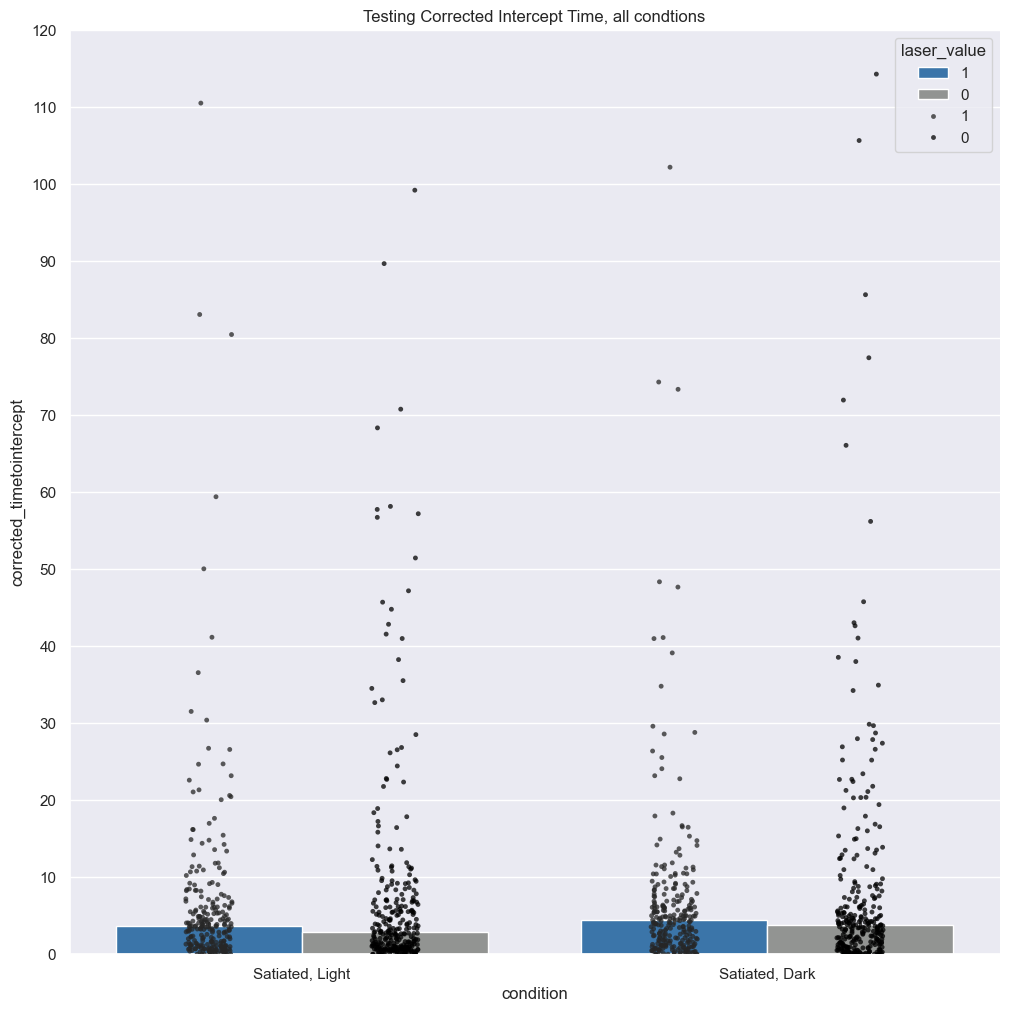

In [188]:
hue_order=[1,0]
palette=['#2976bb','#929591']
plt.figure(figsize=(12,12))
ax=sns.barplot(data=metadata_csv_test, x='condition', y='corrected_timetointercept', hue='laser_value', errorbar=('ci',68), palette=palette, hue_order=hue_order, estimator='median')
ax= sns.stripplot(x='condition', y='corrected_timetointercept', hue='laser_value',dodge=True, data=metadata_csv_test, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Testing Corrected Intercept Time, all condtions')
plt.ylim(0,120)
plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()

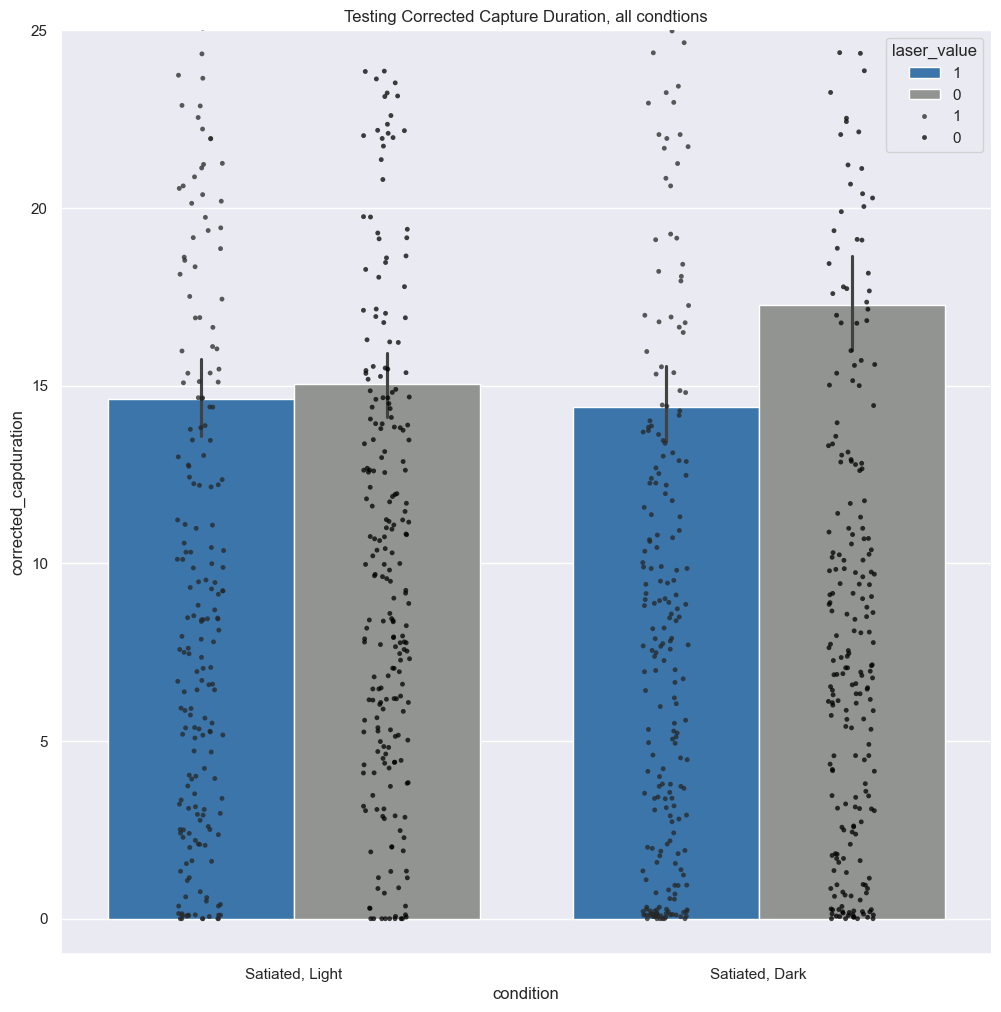

In [200]:
plt.figure(figsize=(12,12))
ax=sns.barplot(data=metadata_csv_test, x='condition', y='corrected_capduration', hue='laser_value', errorbar=('ci',68), palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='corrected_capduration', hue='laser_value',dodge=True, data=metadata_csv_test, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Testing Corrected Capture Duration, all condtions')
plt.ylim(-1,25)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()

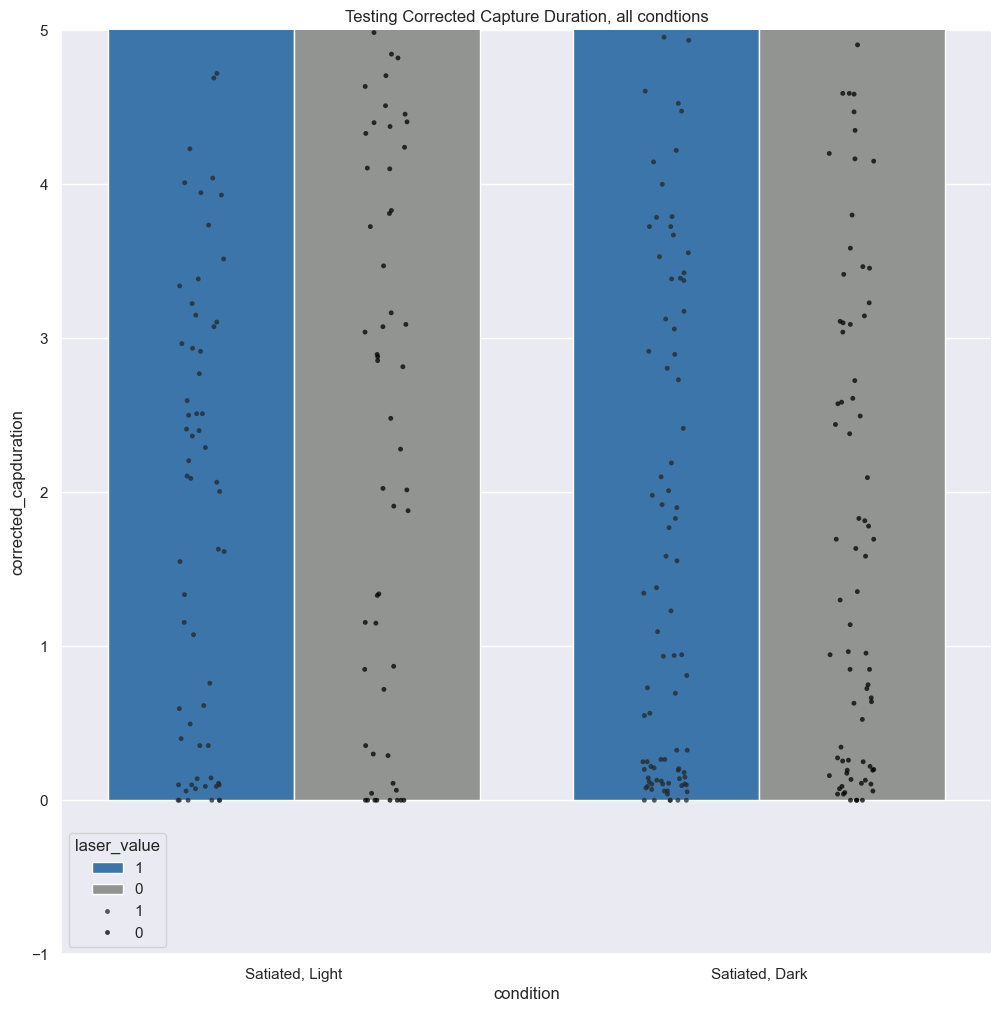

In [197]:
plt.figure(figsize=(12,12))
ax=sns.barplot(data=metadata_csv_test, x='condition', y='corrected_capduration', hue='laser_value', errorbar=('ci',68), palette=palette, hue_order=hue_order, estimator='median')
ax= sns.stripplot(x='condition', y='corrected_capduration', hue='laser_value',dodge=True, data=metadata_csv_test, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Testing Corrected Capture Duration, all condtions')
plt.ylim(-1,5)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()

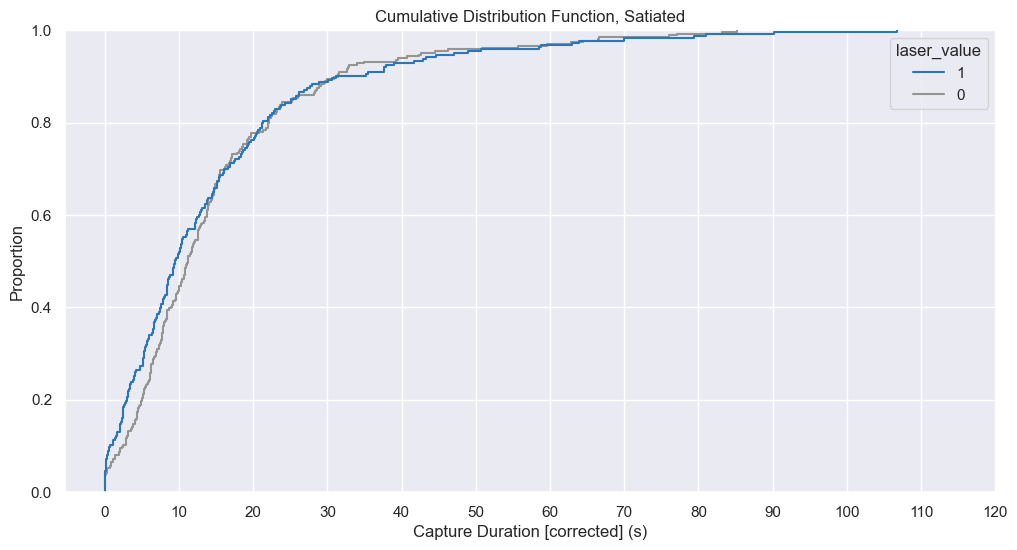

In [208]:
hue_order = [1, 0]  # Adjust this order if necessary
# palette = 'Set1'  # Use an appropriate palette
darkpalette=['#030aa7','#000000']  # Use a different palette for the second plot

# Filter data based on the condition
cond1_data = metadata_csv_test[metadata_csv_test['condition'] == 1]
cond2_data = metadata_csv_test[metadata_csv_test['condition'] == 2]

# Create the figure
fig1 = plt.figure(figsize=(12, 6))

# Plot ECDF for condition 1
sns.ecdfplot(data=cond1_data, 
             x='corrected_capduration', 
             hue='laser_value', 
             hue_order=hue_order, 
             palette=palette)

# Plot ECDF for condition 2
sns.ecdfplot(data=cond2_data, 
             x='corrected_capduration', 
             hue='laser_value', 
             hue_order=hue_order, 
             palette=darkpalette)

# Customize the plot
plt.xlabel('Capture Duration [corrected] (s)')
plt.title('Cumulative Distribution Function, Satiated')
plt.xticks(np.arange(0, 130, 10))
sns.despine()

plt.show()

<Figure size 1200x600 with 0 Axes>

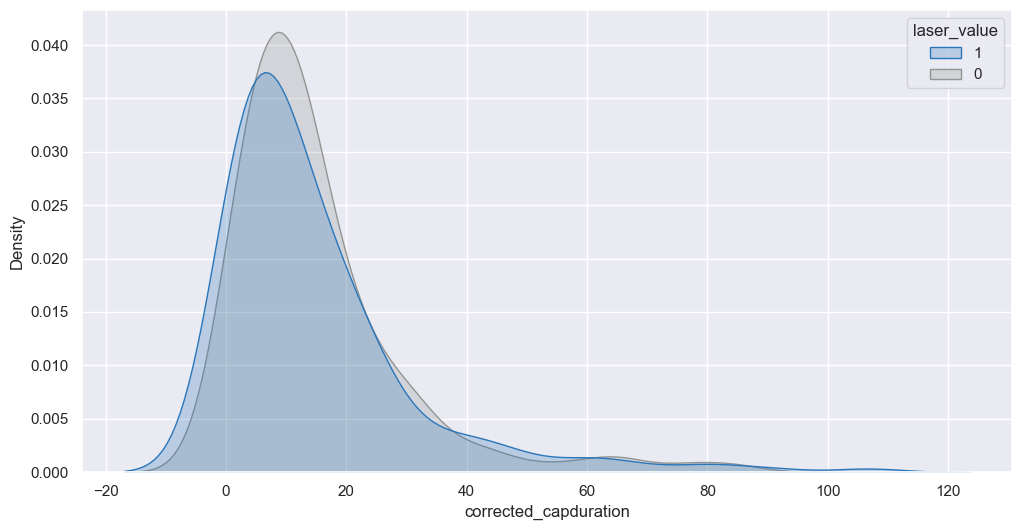

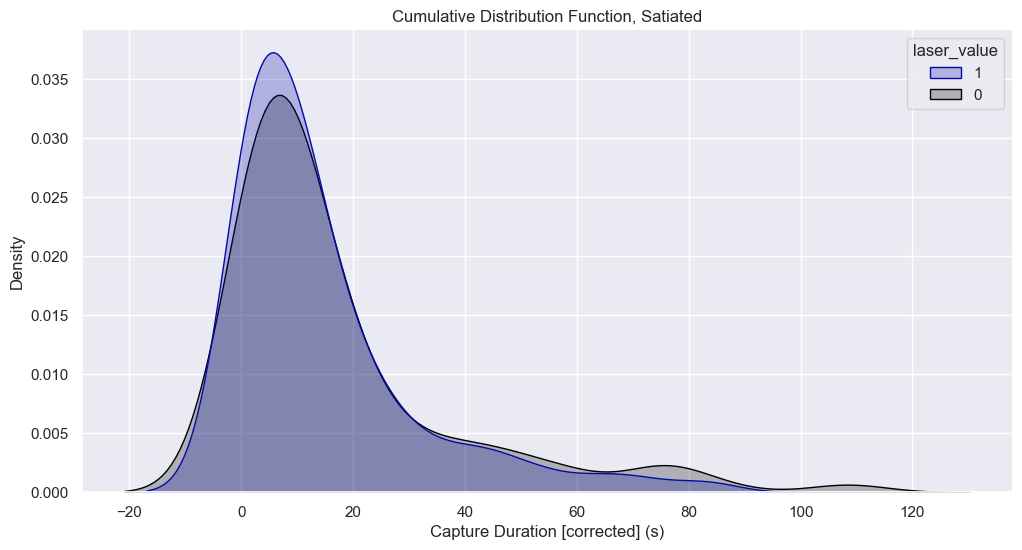

In [220]:
hue_order = [1, 0]  # Adjust this order if necessary
# palette = 'Set1'  # Use an appropriate palette
darkpalette=['#030aa7','#000000']  # Use a different palette for the second plot

# Filter data based on the condition
cond1_data = metadata_csv_test[metadata_csv_test['condition'] == 1]
cond2_data = metadata_csv_test[metadata_csv_test['condition'] == 2]

# Create the figure
fig1 = plt.figure(figsize=(12, 6))

# Plot ECDF for condition 1
fig1 = plt.figure(figsize=(12, 6))
sns.kdeplot(data=cond1_data, 
             x='corrected_capduration', 
             hue='laser_value', 
             hue_order=hue_order, 
             palette=palette, fill=True, common_norm=False)

# Plot ECDF for condition 2
fig2 = plt.figure(figsize=(12, 6))
sns.kdeplot(data=cond2_data, 
             x='corrected_capduration', 
             hue='laser_value', 
             hue_order=hue_order, 
             palette=darkpalette, fill=True, common_norm=False)

# Customize the plot
plt.xlabel('Capture Duration [corrected] (s)')
plt.title('Cumulative Distribution Function, Satiated')
# plt.xticks(np.arange(0, 130, 10))
sns.despine()

plt.show()

<Figure size 1200x600 with 0 Axes>

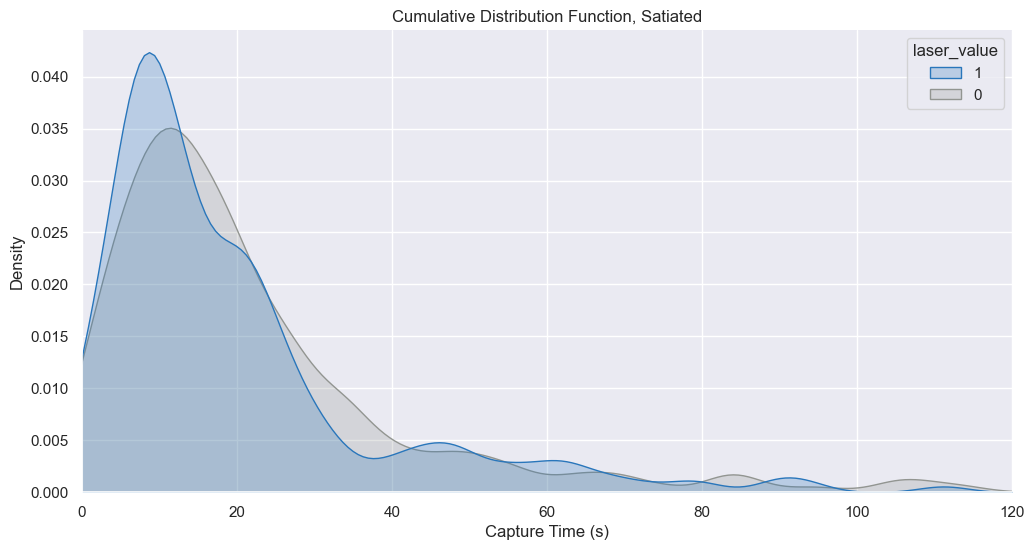

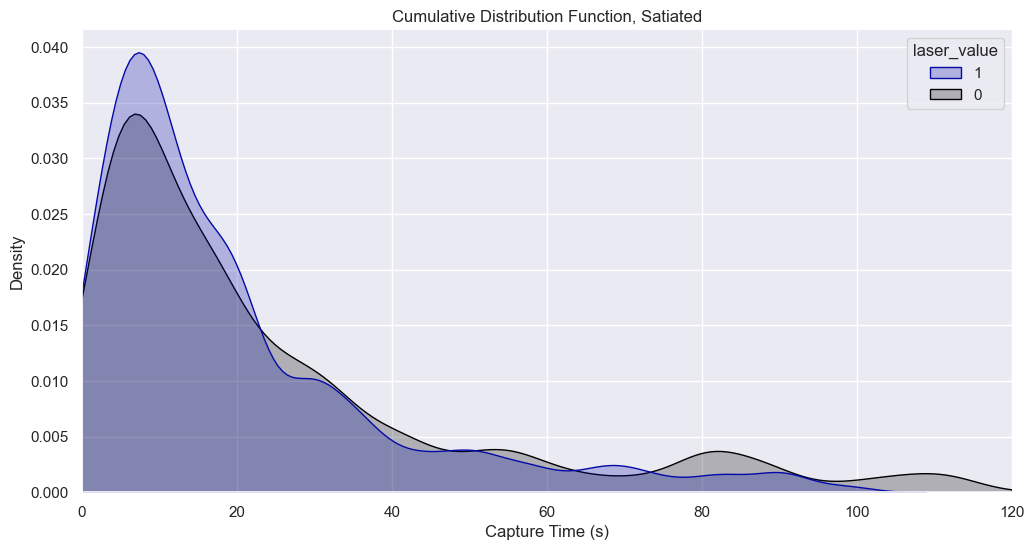

In [235]:
hue_order = [1, 0]  # Adjust this order if necessary
# palette = 'Set1'  # Use an appropriate palette
darkpalette=['#030aa7','#000000']  # Use a different palette for the second plot

# Filter data based on the condition
cond1_data = metadata_csv_test[metadata_csv_test['condition'] == 1]
cond2_data = metadata_csv_test[metadata_csv_test['condition'] == 2]

# Create the figure
fig1 = plt.figure(figsize=(12, 6))

# Plot ECDF for condition 1
fig1 = plt.figure(figsize=(12, 6))
sns.kdeplot(data=cond1_data, 
             x='captureT', 
             hue='laser_value', 
             hue_order=hue_order, 
             palette=palette, fill=True, common_norm=False, bw_adjust=0.5)

plt.xlabel('Capture Time (s)')
plt.title('Cumulative Distribution Function, Satiated')
plt.xlim(0,120)
# plt.xticks(np.arange(0, 130, 10))
sns.despine()

# Plot ECDF for condition 2
fig2 = plt.figure(figsize=(12, 6))
sns.kdeplot(data=cond2_data, 
             x='captureT', 
             hue='laser_value', 
             hue_order=hue_order, 
             palette=darkpalette, fill=True, common_norm=False, bw_adjust=0.5)

# Customize the plot
plt.xlabel('Capture Time (s)')
plt.title('Cumulative Distribution Function, Satiated')
plt.xlim(0,120)
# plt.xticks(np.arange(0, 130, 10))
sns.despine()

plt.show()

<Figure size 1200x600 with 0 Axes>

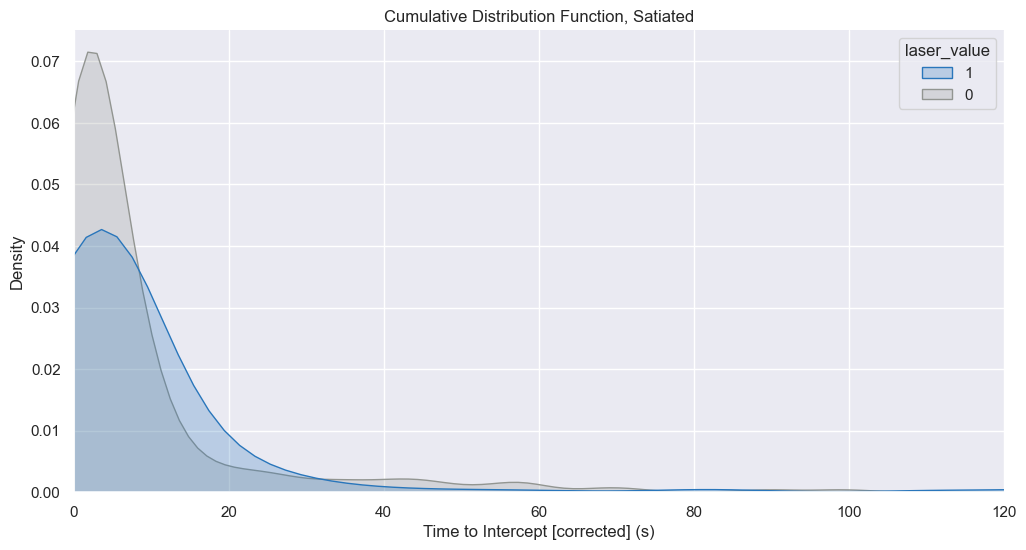

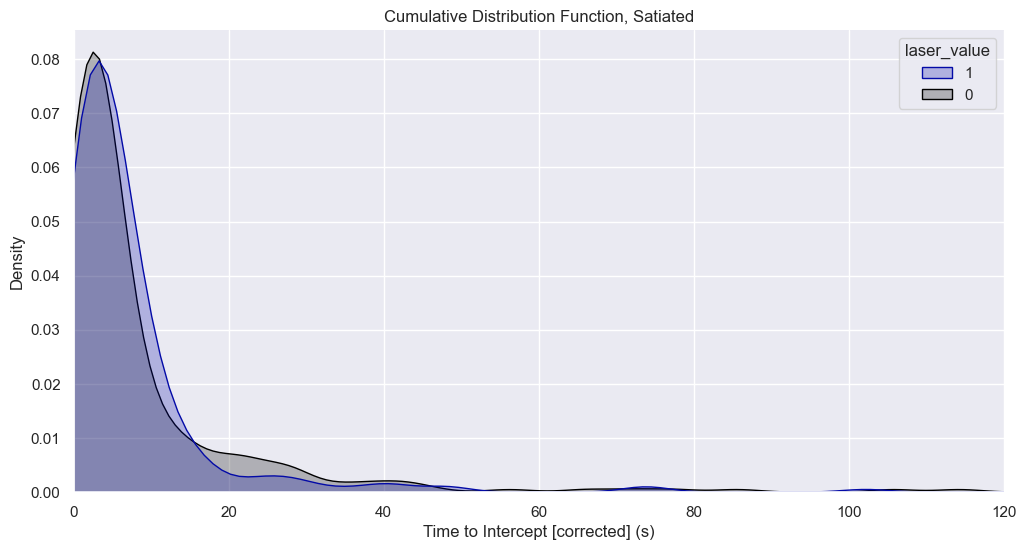

In [232]:
hue_order = [1, 0]  # Adjust this order if necessary
# palette = 'Set1'  # Use an appropriate palette
darkpalette=['#030aa7','#000000']  # Use a different palette for the second plot

# Filter data based on the condition
cond1_data = metadata_csv_test[metadata_csv_test['condition'] == 1]
cond2_data = metadata_csv_test[metadata_csv_test['condition'] == 2]

# Create the figure
fig1 = plt.figure(figsize=(12, 6))

# Plot ECDF for condition 1
fig1 = plt.figure(figsize=(12, 6))
sns.kdeplot(data=cond1_data, 
             x='corrected_timetointercept', 
             hue='laser_value', 
             hue_order=hue_order, 
             palette=palette, fill=True, common_norm=False, bw_adjust=0.5)

plt.xlabel('Time to Intercept [corrected] (s)')
plt.title('Cumulative Distribution Function, Satiated')
plt.xlim(0, 120)
# plt.xticks(np.arange(0, 130, 10))
sns.despine()

# Plot ECDF for condition 2
fig2 = plt.figure(figsize=(12, 6))
sns.kdeplot(data=cond2_data, 
             x='corrected_timetointercept', 
             hue='laser_value', 
             hue_order=hue_order, 
             palette=darkpalette, fill=True, common_norm=False, bw_adjust=0.5)

# Customize the plot
plt.xlabel('Time to Intercept [corrected] (s)')
plt.title('Cumulative Distribution Function, Satiated')
plt.xlim(0, 120)
# plt.xticks(np.arange(0, 130, 10))
sns.despine()

plt.show()

In [4]:
test=geos_df[geos_df['filename'].str.contains('/Volumes/Projects/PreyCapture/ZIActivation/2022-02-15_9-48-27_mouse-0897/Sky_mouse-0897_2022-02-15T09_48_27DLC_dlcrnetms5_optopreycapFeb16shuffle1_150000_el_filtered.csv')]

In [5]:
test

,Unnamed: 0,filename,localframe,dist,az,mouse_spd,cricket_spd
42873,42873,/Volumes/Projects/PreyCapture/ZIActivation/202...,3655,27.178999,4.719848,0.684996,146.685910
42874,42874,/Volumes/Projects/PreyCapture/ZIActivation/202...,3656,26.632780,4.653872,1.353092,198.580128
42875,42875,/Volumes/Projects/PreyCapture/ZIActivation/202...,3677,19.821693,13.413983,1.991268,64.424121
42876,42876,/Volumes/Projects/PreyCapture/ZIActivation/202...,3678,19.780739,15.449357,1.645249,65.699180
42877,42877,/Volumes/Projects/PreyCapture/ZIActivation/202...,3679,19.733270,17.471890,1.658338,62.532196
...,...,...,...,...,...,...,...
43219,43219,/Volumes/Projects/PreyCapture/ZIActivation/202...,4551,4.317015,10.179183,22.788243,4.479453
43220,43220,/Volumes/Projects/PreyCapture/ZIActivation/202...,4552,4.183829,11.227784,22.011716,3.868268
43221,43221,/Volumes/Projects/PreyCapture/ZIActivation/202...,4553,4.096553,9.142573,23.048275,3.254964
43222,43222,/Volumes/Projects/PreyCapture/ZIActivation/202...,4554,4.006048,32.399356,24.270979,3.580931


In [8]:
np.where(test['dist']<3)[0]

array([182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 332, 333,
       334, 335, 336, 337])

In [9]:
test.iloc[182]

Unnamed: 0                                                 43055
filename       /Volumes/Projects/PreyCapture/ZIActivation/202...
localframe                                                  3945
dist                                                    2.771311
az                                                     63.495833
mouse_spd                                               7.273139
cricket_spd                                             5.541243
Name: 43055, dtype: object

In [130]:
np.shape(errors)

(644,)

In [27]:
# error=1
file=metadata_csv['filename'][1]
print(file)

/Volumes/Projects/PreyCapture/ZIActivation/2022-02-15_10-21-03_mouse-0898/Sky_mouse-0898_2022-02-15T10_21_03DLC_dlcrnetms5_optopreycapFeb16shuffle1_150000_el_filtered.csv


In [29]:
test=geos_df[geos_df['filename'].str.contains(file)]
intercepts=np.where(test['dist']<3)[0]
intercept1=intercepts[0]
test
# intercept1
# test['localframe'].iloc[intercept1]

,Unnamed: 0,filename,localframe,dist,az,mouse_spd,cricket_spd
808,808,/Volumes/Projects/PreyCapture/ZIActivation/202...,1308,9.312519,105.015024,5.814175,191.252371
809,809,/Volumes/Projects/PreyCapture/ZIActivation/202...,1309,9.876759,99.547080,4.794040,189.546957
810,810,/Volumes/Projects/PreyCapture/ZIActivation/202...,1310,10.114180,91.385214,4.127716,184.332385
811,811,/Volumes/Projects/PreyCapture/ZIActivation/202...,1311,10.667635,89.056464,3.600594,181.958784
812,812,/Volumes/Projects/PreyCapture/ZIActivation/202...,1312,11.159693,83.139903,3.585104,181.342426
...,...,...,...,...,...,...,...
1482,1482,/Volumes/Projects/PreyCapture/ZIActivation/202...,2572,3.901226,12.400690,19.241788,11.110936
1483,1483,/Volumes/Projects/PreyCapture/ZIActivation/202...,2573,3.899949,16.532667,20.327630,10.444040
1484,1484,/Volumes/Projects/PreyCapture/ZIActivation/202...,2574,3.962124,25.974751,21.529405,9.846475
1485,1485,/Volumes/Projects/PreyCapture/ZIActivation/202...,2575,3.891944,21.220242,21.334705,8.119325


In [124]:
intercepts


array([185, 342, 413, 414, 415, 416, 417, 418, 419, 420])

In [79]:
metadata_csv

,Unnamed: 0,filename,folder_path,condition,laser_value,captureT,cricketdrop,captureframe,freqapproach,timetoapproach,prob_inter,prob_capture,timetointercept,interceptframe,c_length,capduration,trials_to_drop
0,132,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-15_10-01-12_mouse-0897,1,0.0,8.070,1082.0,2696.0,0.116505,1.425,1.000000,0.500000,5.715,1143.0,12.67000,2.355,NaN
1,133,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-15_10-21-03_mouse-0898,1,0.0,6.425,1299.0,2584.0,0.135166,1.150,1.000000,0.333333,2.450,490.0,9.13875,3.975,NaN
2,134,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-15_10-23-08_mouse-0898,1,0.0,21.990,1029.0,5427.0,0.166412,5.025,0.500000,0.333333,16.445,3289.0,12.04850,5.545,NaN
3,135,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-15_10-25-25_mouse-0898,1,0.0,21.860,1170.0,5542.0,0.163778,15.225,0.666667,0.250000,18.140,3628.0,12.87850,3.720,NaN
4,136,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-15_10-27-44_mouse-0898,1,0.0,22.940,1090.0,5678.0,0.165798,0.075,0.428571,0.333333,0.755,151.0,13.93075,22.185,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1104,2435,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-25-16_mouse-1430,2,1.0,22.525,1805.0,6310.0,0.141276,1.945,0.666667,0.250000,6.905,1381.0,9.36850,15.620,left_only
1105,2436,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-27-15_mouse-1430,2,0.0,12.125,1513.0,3938.0,0.197472,0.250,0.200000,1.000000,11.625,2325.0,10.74700,0.500,left_only
1106,2437,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-29-34_mouse-1430,2,1.0,6.740,1766.0,3114.0,0.040080,6.185,1.000000,1.000000,6.720,1344.0,10.24200,0.020,left_only
1107,2438,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-30-57_mouse-1430,2,0.0,NaN,1494.0,43611.0,0.163335,8.170,0.263158,0.100000,27.820,5564.0,7.58625,NaN,left_only


In [80]:
#merge the two dfs so that all rows of the geometries have an associated condition and laser value
merged_df = pd.merge(geos_df, metadata_small, on='filename', how='left')

In [81]:
merged_df

,Unnamed: 0,filename,localframe,dist,az,mouse_spd,cricket_spd,condition,laser_value
0,0,/Volumes/Projects/PreyCapture/ZIActivation/202...,1087,11.713119,171.506417,6.418692,139.121474,1,0.0
1,1,/Volumes/Projects/PreyCapture/ZIActivation/202...,1088,12.039882,179.091308,7.832069,130.150670,1,0.0
2,2,/Volumes/Projects/PreyCapture/ZIActivation/202...,1089,12.077035,175.622398,8.852334,141.281868,1,0.0
3,3,/Volumes/Projects/PreyCapture/ZIActivation/202...,1090,12.172264,172.377686,9.765431,150.217841,1,0.0
4,4,/Volumes/Projects/PreyCapture/ZIActivation/202...,1091,12.683908,163.427985,8.215556,151.200106,1,0.0
...,...,...,...,...,...,...,...,...,...
6871091,6871091,/Volumes/Projects/PreyCapture/ZIActivation/202...,9778,3.827463,15.730165,31.409355,13.160123,2,1.0
6871092,6871092,/Volumes/Projects/PreyCapture/ZIActivation/202...,9779,3.702472,15.736844,30.618819,11.743372,2,1.0
6871093,6871093,/Volumes/Projects/PreyCapture/ZIActivation/202...,9780,3.610869,13.730883,28.749787,7.466669,2,1.0
6871094,6871094,/Volumes/Projects/PreyCapture/ZIActivation/202...,9781,3.636880,16.927689,31.135584,6.499485,2,1.0


In [82]:
#look at means/ medians and see if grouping by condition reveals any trends
merged_df.groupby(['condition', 'laser_value']).mean(numeric_only=True)

Unnamed: 0    localframe       dist         az  \
condition laser_value                                                     
1         0.0          2.620760e+06  18437.278872  34.037532  74.769941   
          1.0          3.276800e+06  24366.278689  35.138160  68.168364   
2         0.0          4.008918e+06  13993.864357  31.355854  80.108524   
          1.0          4.356424e+06  13323.691342  31.301099  77.317280   

                       mouse_spd  cricket_spd  
condition laser_value                          
1         0.0           9.759515     8.220839  
          1.0           6.857601    12.018866  
2         0.0          12.675972     9.866387  
          1.0          13.570865     8.641221

In [94]:
metadata_csv.groupby(['condition', 'laser_value']).mean(numeric_only=True)

Unnamed: 0   captureT  cricketdrop  captureframe  \
condition laser_value                                                      
1         0.0          1171.418685  21.730095  1602.200692   9730.522491   
          1.0          1265.398438  19.905583  1986.183594  12599.335938   
2         0.0          1280.038194  24.519648  1581.815972   8734.902778   
          1.0          1387.324723  20.173574  1902.738007   7360.837638   

                       freqapproach  timetoapproach  prob_inter  prob_capture  \
condition laser_value                                                           
1         0.0              0.142955        4.186869    0.587328      0.452531   
          1.0              0.115350        5.297891    0.609347      0.495688   
2         0.0              0.127150        3.400104    0.553028      0.571345   
          1.0              0.117017        3.508745    0.555120      0.590823   

                       timetointercept  interceptframe   c_length  capduration  
condition laser_value                                                           
1         0.0                13.813028     2762.605536  12.212932    11.316780  
          1.0                19.402910     3880.582031  14.995685    11.259350  
2         0.0                13.266458     2653.291667   9.625181    13.753000  
          1.0                11.362472     2272.494465   9.502850    10.896673

In [29]:
type(merged_df['condition'][0])

numpy.float64

In [45]:
light_trials=merged_df[merged_df['condition']==1]
dark_trials=merged_df[merged_df['condition']==2]

In [76]:
light_trials['filename'].nunique()

531

In [77]:
dark_trials['filename'].nunique()


554

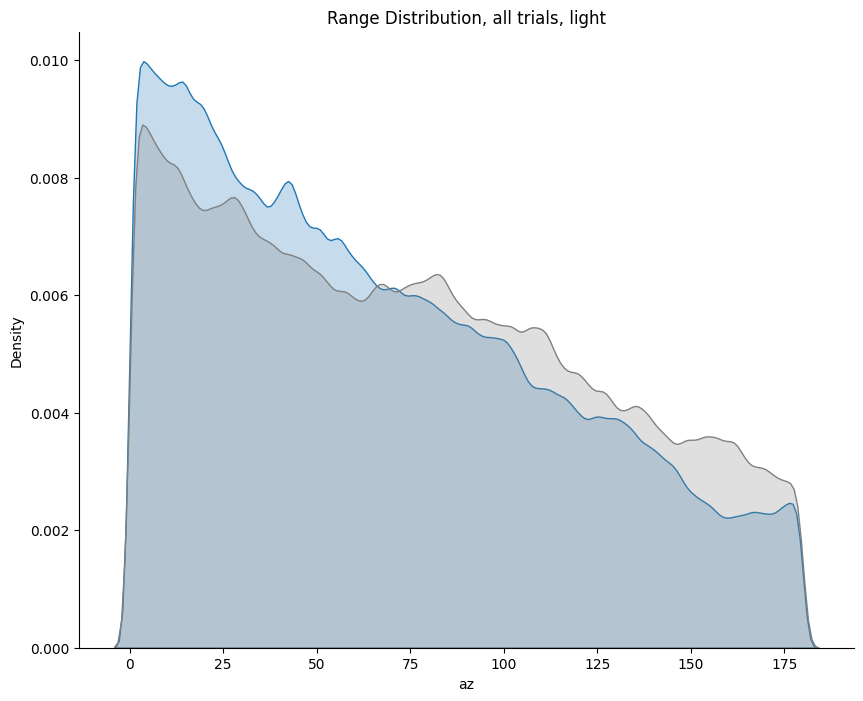

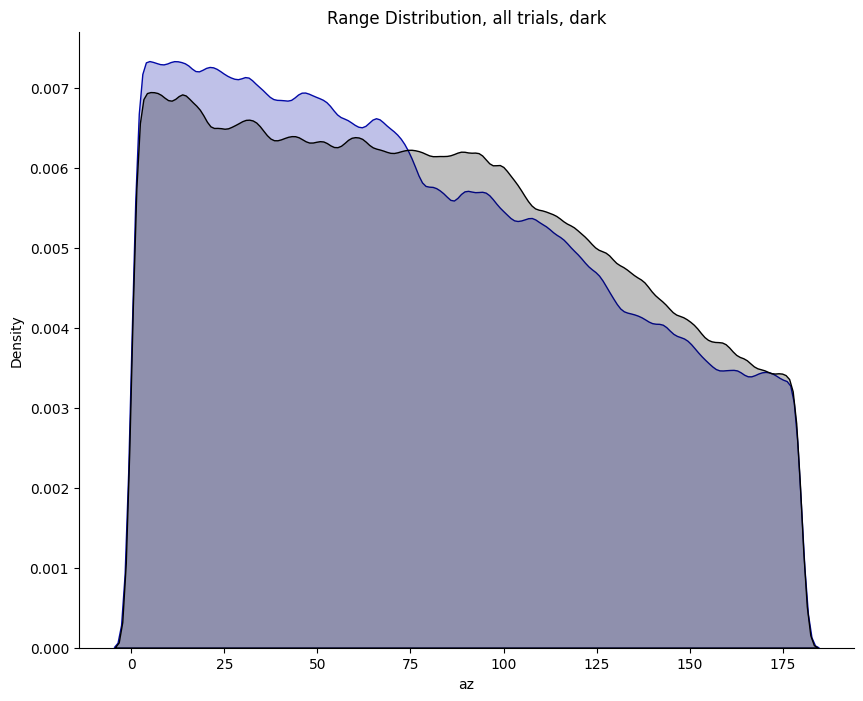

In [83]:
# visualize distrbutions as kde and cdf
# these might look slightly different because original plots were intercept to catch, these are drop to catch
# metadata should have intercept frame and could limit data to that period to check
# could also look at distributions from drop to intercept

plt.figure(figsize=(10,8))
sns.kdeplot(data=light_trials[light_trials['laser_value']==1], x='az', fill=True, bw_adjust=0.5)
sns.kdeplot(data=light_trials[light_trials['laser_value']==0], x='az', fill=True, color='grey', bw_adjust=0.5 )
# plt.legend(labels=labels)
plt.title('Range Distribution, all trials, light')
# plt.xlim(0,200)
# plt.xticks(np.arange(0,200,25))
# plt.ylim(0,0.012)
sns.despine()

plt.figure(figsize=(10,8))
sns.kdeplot(data=dark_trials[dark_trials['laser_value']==1], x='az', fill=True, color='#030aa7',bw_adjust=0.5)
sns.kdeplot(data=dark_trials[dark_trials['laser_value']==0], x='az', fill=True, color='#000000', bw_adjust=0.5 )
# plt.legend(labels=labels)
plt.title('Range Distribution, all trials, dark')
# plt.xlim(0,200)
# plt.xticks(np.arange(0,200,25))
# plt.ylim(0,0.008)
sns.despine()

In [ ]:
calculate ks stats for each of the different geos under different conditions 

In [61]:
stats.ks_2samp(dark_trials[dark_trials['laser_value']==1]['az'], dark_trials[dark_trials['laser_value']==0]['az'], method='auto', nan_policy='omit')

KstestResult(statistic=0.03328556823660689, pvalue=0.0, statistic_location=73.8269647639184, statistic_sign=1)

In [64]:
stats.ks_2samp(light_trials[light_trials['laser_value']==1]['az'], light_trials[light_trials['laser_value']==0]['az'], method='auto', nan_policy='omit')

KstestResult(statistic=0.062348204290409714, pvalue=0.0, statistic_location=65.50743800451885, statistic_sign=1)